Cargando y preparando los datos del dataset MNIST...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dimensiones de entrenamiento: (60000, 784)
Dimensiones de prueba: (10000, 784)

--- Probando arquitectura: Red Pequeña (1 capa oculta) ---
Epoch 1/5


C:\Users\Pc\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8700 - loss: 0.4767 - val_accuracy: 0.9298 - val_loss: 0.2510
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9345 - loss: 0.2292 - val_accuracy: 0.9450 - val_loss: 0.1956
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9490 - loss: 0.1763 - val_accuracy: 0.9553 - val_loss: 0.1589
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9583 - loss: 0.1440 - val_accuracy: 0.9607 - val_loss: 0.1410
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9649 - loss: 0.1204 - val_accuracy: 0.9647 - val_loss: 0.1281
-> Resultado para Red Pequeña (1 capa oculta) -> Precisión en Test: 96.08%

--- Probando arquitectura: Red Mediana (2 capas ocultas) ---
Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8940 - loss: 0.3759 - val_accuracy: 0.9483 - val_loss: 0.1803
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9546 - loss: 0.1570 - val_accuracy: 0.9592 - v

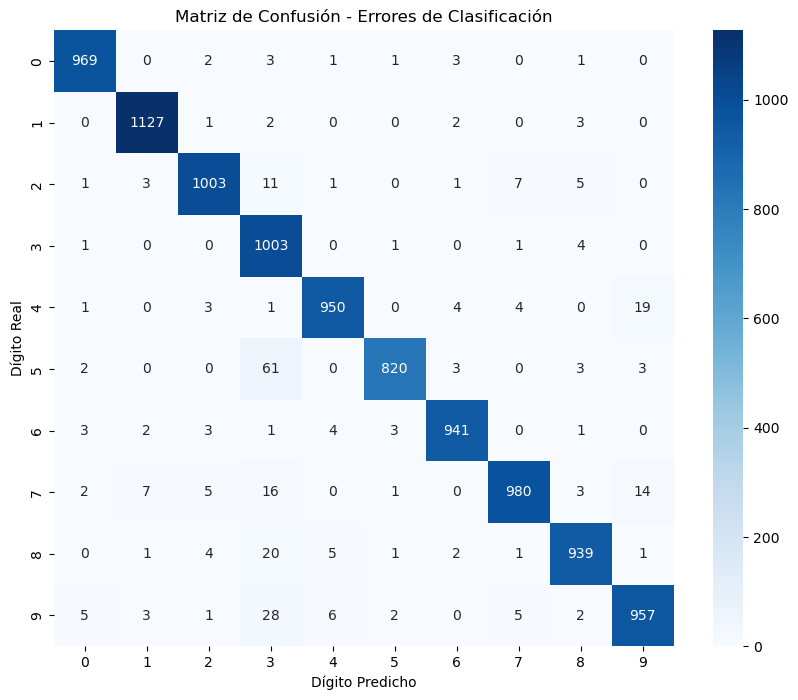

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 1. Cargar y preparar el dataset MNIST
print("Cargando y preparando los datos del dataset MNIST...")
(X_entrenamiento, y_entrenamiento), (X_prueba, y_prueba) = mnist.load_data()

# Normalizar los píxeles (de 0-255 a un rango de 0.0 a 1.0)
X_entrenamiento = X_entrenamiento.astype('float32') / 255.0
X_prueba = X_prueba.astype('float32') / 255.0

# Reformatear las imágenes de 28x28 a vectores planos de 784 valores
X_entrenamiento = X_entrenamiento.reshape((60000, 784))
X_prueba = X_prueba.reshape((10000, 784))

print(f"Dimensiones de entrenamiento: {X_entrenamiento.shape}")
print(f"Dimensiones de prueba: {X_prueba.shape}\n")

# 2. Experimentar con diferentes arquitecturas de redes neuronales
def experimentar_con_arquitecturas():
    """Plantilla adaptada para experimentar con diferentes redes, optimizando hiperparámetros"""
    
    arquitecturas = [
        {"capas": [64], "nombre": "Red Pequeña (1 capa oculta)"},
        {"capas": [128, 64], "nombre": "Red Mediana (2 capas ocultas)"},
        {"capas": [256, 128, 64], "nombre": "Red Grande (3 capas ocultas)"}
    ]

    resultados = []
    modelos_entrenados = {}

    for arq in arquitecturas:
        print(f"--- Probando arquitectura: {arq['nombre']} ---")
        
        # Construcion modelo secuencial
        modelo = models.Sequential()
        modelo.add(layers.Dense(arq['capas'][0], activation='relu', input_shape=(784,)))
        
        for neuronas in arq['capas'][1:]:
            modelo.add(layers.Dense(neuronas, activation='relu'))
            
        # Capa de salida con 10 neuronas (dígitos del 0 al 9) y activación softmax
        modelo.add(layers.Dense(10, activation='softmax'))

        # Compilar el modelo 
        modelo.compile(optimizer='adam',
                      loss='sparse_categorical_crossentropy',
                      metrics=['accuracy'])

        # Entrenar el modelo (con optimización de épocas y lotes)
        historia = modelo.fit(X_entrenamiento, y_entrenamiento,
                              epochs=5, batch_size=128, 
                              validation_split=0.2, verbose=1)

        # Evaluar con los datos de prueba
        pérdida, precisión = modelo.evaluate(X_prueba, y_prueba, verbose=0)
        resultados.append({"arquitectura": arq['nombre'], "precisión": precisión})
        modelos_entrenados[arq['nombre']] = modelo
        
        print(f"-> Resultado para {arq['nombre']} -> Precisión en Test: {precisión:.2%}\n")

    return resultados, modelos_entrenados

# Ejecutar el experimento
resultados_experimento, modelos = experimentar_con_arquitecturas()

# Resumen de resultados
print("==========================================")
print("RESUMEN DE PRECISIÓN POR ARQUITECTURA:")
print("==========================================")
for res in resultados_experimento:
    print(f"• {res['arquitectura']}: {res['precisión']:.2%}")


# 3. Análisis de Errores (¿Qué dígitos se confunden más y por qué?)
print("\nAnalizando errores del mejor modelo (Red Grande)...")
mejor_modelo = modelos["Red Grande (3 capas ocultas)"]

# Realizar predicciones en el conjunto de prueba
predicciones_prob = mejor_modelo.predict(X_prueba)
predicciones_clases = np.argmax(predicciones_prob, axis=1)

# Generar matriz de confusión para ver confusiones entre clases
matriz_conf = confusion_matrix(y_prueba, predicciones_clases)

# Visualizar la matriz de confusión mediante un mapa de calor
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues', 
            xticklabels=range(10), yticklabels=range(10))
plt.title('Matriz de Confusión - Errores de Clasificación')
plt.xlabel('Dígito Predicho')
plt.ylabel('Dígito Real')
plt.show()